# WaferPi · Visualización de defectos en obleas semiconductoras (WM-811K)

**Proyecto de Visualización de Datos — Maestría en Inteligencia Artificial (ITA)**
Autor: Bryan Guadalupe De la paz Coronado

**Pregunta analítica (desde el Avance 1):** ¿es posible distinguir visualmente el tipo de patrón de falla de una oblea a partir de la distribución espacial de sus dies fallados?

Este notebook reúne **todo el proyecto en un solo flujo reproducible**:

| Sección | Qué hace |
|---|---|
| 0. Configuración | Librerías, rutas y paleta de colores |
| 1. Carga de datos | Lee el archivo original `LSWMD.pkl` |
| 2. Limpieza y variables derivadas | Desenvuelve etiquetas, calcula % de dies fallados |
| 3. EDA (Avance 2) | Reproduce las 4 visualizaciones exploratorias |
| 4. Visualizaciones finales (Avance 3) | 4.1 estática mejorada · 4.2 interactiva |
| 5. Exportación para Tableau | Genera el CSV que usa el dashboard de BI |

> **Antes de correrlo:** sigue las instrucciones del `README.md` (Python 3.11, `pip install -r requirements.txt` y descargar `LSWMD.pkl` en la carpeta `data/`).

## 0. Configuración
Todas las rutas son **relativas a la carpeta del repositorio**, así el notebook funciona en cualquier computadora sin cambiar nada.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Carpeta raíz del repo (este notebook vive en notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_DATOS = RAIZ / "data" / "LSWMD.pkl"            # archivo original (no se modifica nunca)
CARPETA_PROCESADOS = RAIZ / "data" / "processed"    # datos derivados
CARPETA_FIGURAS = RAIZ / "figures"
CARPETA_PROCESADOS.mkdir(parents=True, exist_ok=True)
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Paleta compartida por todas las figuras (mismo color = mismo significado)
AZUL = ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"]   # magnitud (densidad)
NARANJA = "#eb6834"                                                # resumen / die fallado
GRIS_DIE = "#d6d5cf"                                               # die bueno
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

print("pandas", pd.__version__, "| numpy", np.__version__)
print("Datos esperados en:", RUTA_DATOS, "->", "OK" if RUTA_DATOS.exists() else "NO ENCONTRADO (ver README)")

pandas 1.5.3 | numpy 1.26.4
Datos esperados en: /home/claude/waferpi_visual/data/LSWMD.pkl -> OK


## 1. Carga de datos

**Dataset:** WM-811K (Wu, Jang y Chen, 2015) — 811,457 mapas de oblea de 46,293 lotes de fabricación reales.
**Fuente:** Kaggle, *WM-811K wafer map* — https://www.kaggle.com/datasets/qingyi/wm811k-wafer-map (archivo `LSWMD.pkl`, ~2.1 GB).

> ⚠️ `LSWMD.pkl` se guardó con una versión muy antigua de pandas. Con pandas 2.x falla con `No module named 'pandas.indexes'`; por eso el proyecto fija **pandas 1.5.3 y numpy < 2** (ver `requirements.txt`). La carga tarda alrededor de 1 minuto y usa ~3 GB de RAM.

In [2]:
df = pd.read_pickle(RUTA_DATOS)

print("Obleas:", f"{len(df):,}")
print("Columnas:", list(df.columns))
df[["dieSize", "lotName", "waferIndex", "trianTestLabel", "failureType"]].head()

Obleas: 811,457
Columnas: ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']


,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,1683.0,lot1,1.0,[[Training]],[[none]]
1,1683.0,lot1,2.0,[[Training]],[[none]]
2,1683.0,lot1,3.0,[[Training]],[[none]]
3,1683.0,lot1,4.0,[[Training]],[[none]]
4,1683.0,lot1,5.0,[[Training]],[[none]]


| Columna | Contenido |
|---|---|
| `waferMap` | Matriz 2D por oblea: **0** = fuera de la oblea, **1** = die bueno, **2** = die fallado |
| `dieSize` | Número de dies de la oblea |
| `lotName`, `waferIndex` | Lote de fabricación y posición de la oblea en el lote (1–25) |
| `trianTestLabel` | Partición original *Training* / *Test* (el nombre trae el error de dedo del dataset original) |
| `failureType` | Patrón de falla: 8 patrones + `none` (sin patrón). Solo 172,950 obleas están etiquetadas |

## 2. Limpieza y variables derivadas

Transformaciones aplicadas (todas en código, ninguna manual):

1. **Desenvolver etiquetas.** `failureType` y `trianTestLabel` vienen como arreglos anidados (`array([['Center']])`) o vacíos. Se convierten a texto simple (`'Center'`) o a `NaN` si no hay etiqueta.
2. **Contar dies por oblea.** `dies_totales` = celdas ≠ 0 y `dies_fallados` = celdas = 2 del `waferMap`.
3. **% de dies fallados.** `pct_fallados = 100 · dies_fallados / dies_totales`.
4. **Subconjunto etiquetado.** `etiquetadas` = obleas con `patron` conocido (incluye `none`), que es el universo de las comparaciones por patrón.

El archivo original no se modifica: todo vive en memoria y lo que se guarda va a `data/processed/`.

In [3]:
def desenvolver(valor):
    # array([['Center']]) -> 'Center'   |   array([]) -> None
    arr = np.asarray(valor)
    return None if arr.size == 0 else str(arr.reshape(-1)[0])

df["patron"] = df["failureType"].map(desenvolver)
df["conjunto"] = df["trianTestLabel"].map(desenvolver)

df["dies_totales"] = df["waferMap"].map(lambda m: int((np.asarray(m) != 0).sum()))
df["dies_fallados"] = df["waferMap"].map(lambda m: int((np.asarray(m) == 2).sum()))
df["pct_fallados"] = 100 * df["dies_fallados"] / df["dies_totales"]

# Verificación: dieSize debe ser exactamente el número de dies de cada mapa
print("¿dieSize == dies_totales en todas las obleas?", bool((df["dieSize"] == df["dies_totales"]).all()))

etiquetadas = df[df["patron"].notna()].copy()
print(f"Obleas etiquetadas: {len(etiquetadas):,} de {len(df):,} ({len(etiquetadas)/len(df):.1%})")
etiquetadas["patron"].value_counts()

¿dieSize == dies_totales en todas las obleas? True


Obleas etiquetadas: 172,950 de 811,457 (21.3%)


none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: patron, dtype: int64

**Hallazgo de la limpieza:** `dieSize` coincide exactamente con el número de dies del mapa. Por eso en este avance el eje se nombra **"número de dies por oblea"** y no "tamaño de oblea" como en el Avance 2: todas las obleas tienen el mismo tamaño físico, y lo que cambia es cuántos dies (chips) caben según el diseño del producto.

## 3. EDA — visualizaciones del Avance 2

Se reproducen tal como se entregaron en el Avance 2 (matplotlib básico), para tener la referencia contra la que se comparan las versiones finales.

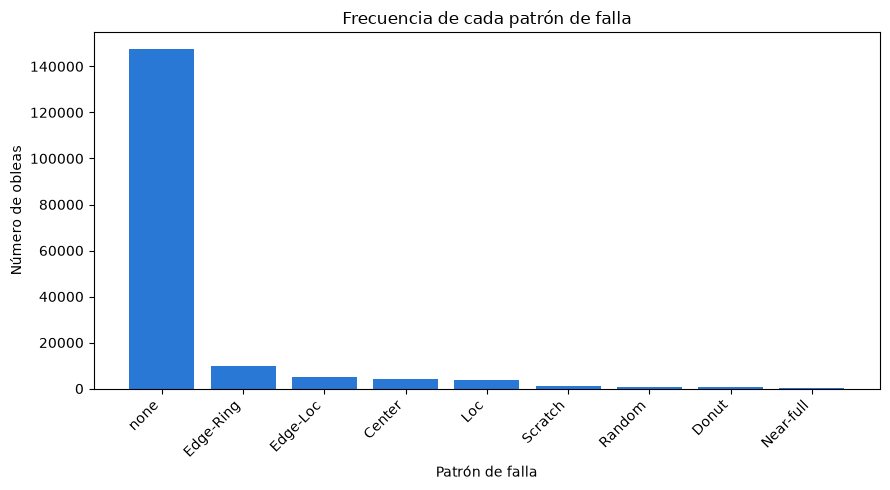

none         85.24
Edge-Ring     5.60
Edge-Loc      3.00
Center        2.48
Loc           2.08
Scratch       0.69
Random        0.50
Donut         0.32
Near-full     0.09
Name: patron, dtype: float64


In [4]:
# 3.1 Univariada: frecuencia de cada patrón
conteo = etiquetadas["patron"].value_counts()
plt.figure(figsize=(9, 5))
plt.bar(conteo.index, conteo.values, color="#2a78d6")
plt.xlabel("Patrón de falla"); plt.ylabel("Número de obleas")
plt.title("Frecuencia de cada patrón de falla")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "avance2_univariada.png", dpi=150); plt.show()
print((100 * conteo / conteo.sum()).round(2))

Correlación de Pearson: -0.2207


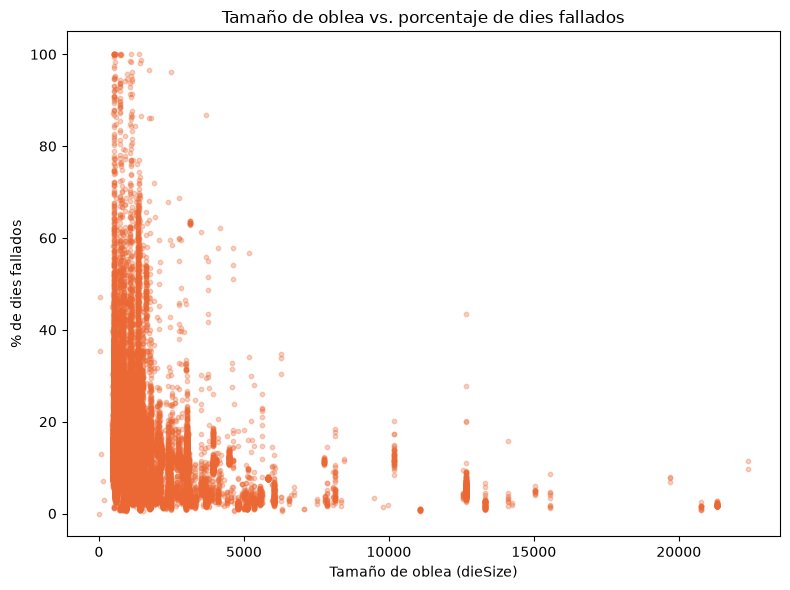

In [5]:
# 3.2 Bivariada: dieSize vs % de dies fallados (versión original del Avance 2)
print("Correlación de Pearson:", round(etiquetadas["dieSize"].corr(etiquetadas["pct_fallados"]), 4))
plt.figure(figsize=(8, 6))
plt.scatter(etiquetadas["dieSize"], etiquetadas["pct_fallados"], alpha=0.3, s=10, color="#eb6834")
plt.xlabel("Tamaño de oblea (dieSize)"); plt.ylabel("% de dies fallados")
plt.title("Tamaño de oblea vs. porcentaje de dies fallados"); plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "avance2_bivariada.png", dpi=150); plt.show()

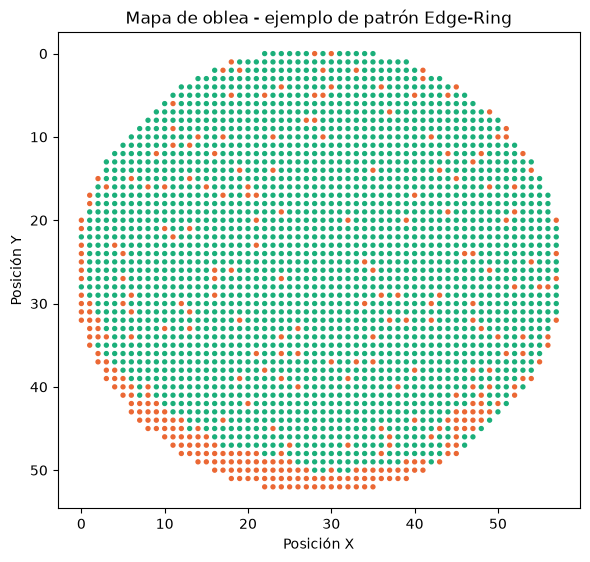

In [6]:
# 3.3 Multivariada: mapa de una oblea (posición X, Y y estado del die)
ejemplo = np.asarray(etiquetadas.loc[etiquetadas["patron"] == "Edge-Ring", "waferMap"].iloc[0])
ys, xs = np.where(ejemplo != 0)
colores = ["#1baf7a" if v == 1 else "#eb6834" for v in ejemplo[ys, xs]]
plt.figure(figsize=(6, 6))
plt.scatter(xs, ys, c=colores, s=8)
plt.gca().invert_yaxis(); plt.gca().set_aspect("equal")
plt.title("Mapa de oblea - ejemplo de patrón Edge-Ring")
plt.xlabel("Posición X"); plt.ylabel("Posición Y"); plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "avance2_multivariada.png", dpi=150); plt.show()

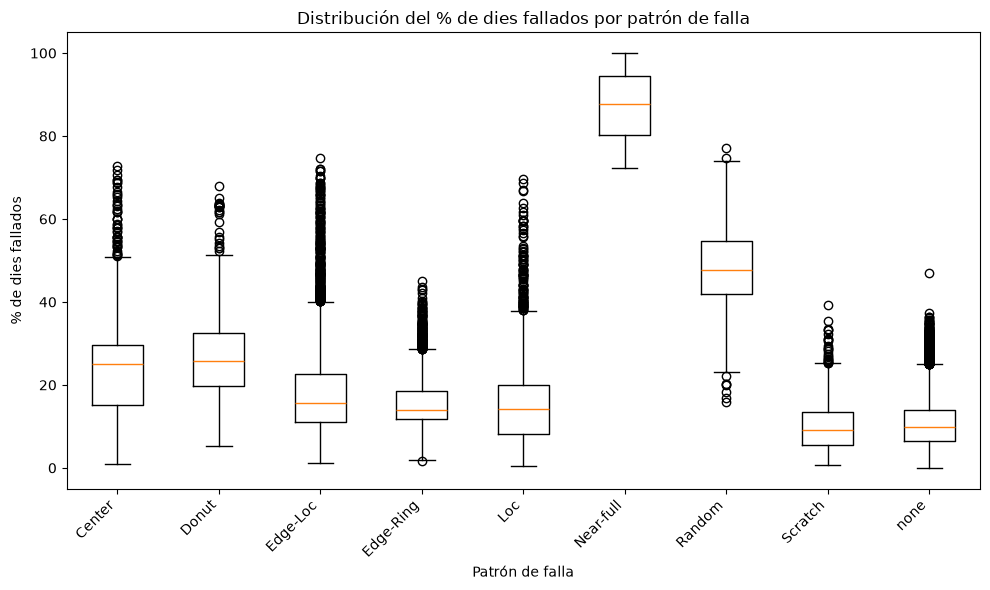

patron
Near-full    87.8
Random       47.7
Donut        25.8
Center       25.0
Edge-Loc     15.6
Loc          14.2
Edge-Ring    14.0
none          9.8
Scratch       9.2
Name: pct_fallados, dtype: float64


In [7]:
# 3.4 Condicional: % de dies fallados por patrón
patrones = sorted(etiquetadas["patron"].unique())
plt.figure(figsize=(10, 6))
plt.boxplot([etiquetadas.loc[etiquetadas["patron"] == p, "pct_fallados"] for p in patrones], tick_labels=patrones)
plt.xlabel("Patrón de falla"); plt.ylabel("% de dies fallados")
plt.title("Distribución del % de dies fallados por patrón de falla")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "avance2_condicional.png", dpi=150); plt.show()
print(etiquetadas.groupby("patron")["pct_fallados"].median().sort_values(ascending=False).round(1))

## 4. Visualizaciones finales (Avance 3)

### 4.1 Herramienta estática (matplotlib): número de dies vs % de dies fallados

Problemas de la versión del Avance 2 y cómo se corrigen:

| Problema en el Avance 2 | Mejora |
|---|---|
| **Sobretrazado:** 172,950 puntos encimados; no se ve dónde se concentran | **Hexbin** con color por número de obleas (escala log) |
| 95% de las obleas queda aplastado en el primer 10% del eje X | **Eje X logarítmico** |
| La tendencia no se lee; solo se veía r = −0.22 | **Mediana y rango intercuartil por rango de dieSize**, más Spearman ρ (relación monótona) |
| Los pocos puntos con > 50% de fallo dominaban visualmente | **Anotación** que los cuantifica (0.4%) |
| Eje "Tamaño de oblea" incorrecto y título descriptivo | Eje **"número de dies por oblea"** y **título que enuncia el hallazgo** |

In [8]:
e = etiquetadas
r = e["dieSize"].corr(e["pct_fallados"])                      # relación lineal
rho = e["dieSize"].corr(e["pct_fallados"], method="spearman")  # relación monótona (por rangos)

# Mediana y cuartiles del % de fallo dentro de rangos de dieSize
bordes = [250, 500, 520, 600, 800, 1000, 1250, 1500, 2000, 3000, 5000, 10000, 23000]
resumen = (e.assign(rango=pd.cut(e["dieSize"], bordes))
             .groupby("rango")
             .agg(x=("dieSize", "median"), med=("pct_fallados", "median"),
                  q1=("pct_fallados", lambda s: s.quantile(0.25)),
                  q3=("pct_fallados", lambda s: s.quantile(0.75)), n=("pct_fallados", "size"))
             .dropna())
resumen = resumen[resumen["n"] >= 100]          # solo rangos con suficientes obleas
repunte = e[(e["dieSize"] > 2000) & (e["dieSize"] <= 5000)]
pct_edge_ring = (repunte["patron"] == "Edge-Ring").mean() * 100
resumen.round(1)

,x,med,q1,q3,n
rango,,,,,
"(250, 500]",497.0,11.6,10.2,13.3,1905
"(500, 520]",516.0,17.4,14.3,20.7,31751
"(520, 600]",562.0,11.2,7.1,15.6,30805
"(600, 800]",776.0,11.6,10.2,13.4,22996
"(800, 1000]",895.0,9.2,7.3,12.0,15053
"(1000, 1250]",1109.0,8.3,5.5,10.6,27822
"(1250, 1500]",1414.0,6.2,3.7,9.4,26583
"(1500, 2000]",1534.0,5.6,4.1,9.6,7476
"(2000, 3000]",2126.0,11.7,8.1,12.7,3388


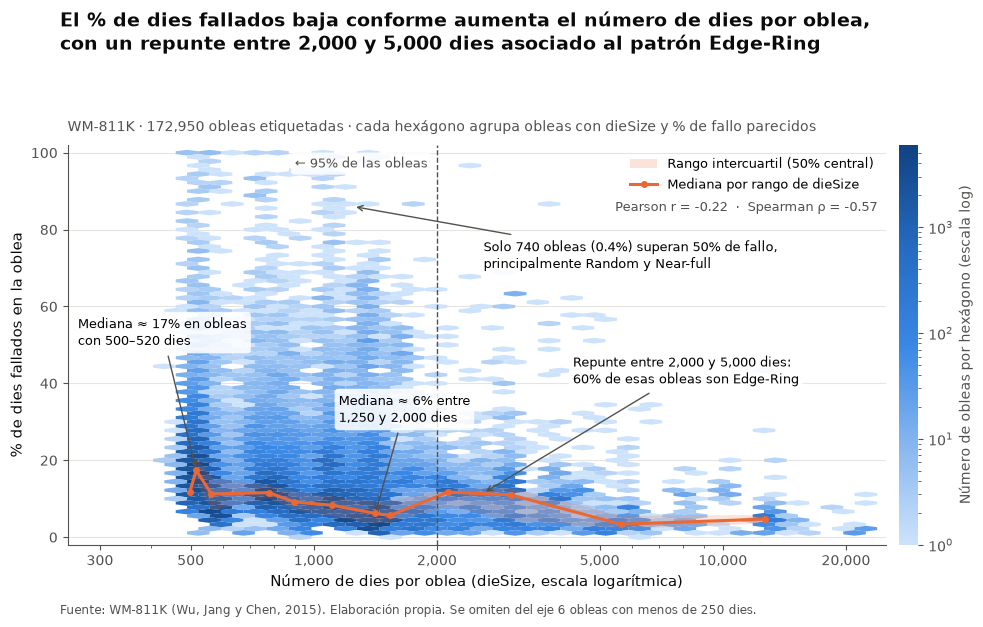

In [9]:
plt.rcParams.update({"axes.edgecolor": TINTA2, "axes.labelcolor": TINTA,
                     "xtick.color": TINTA2, "ytick.color": TINTA2})
fig, ax = plt.subplots(figsize=(10, 6.2))

# Capa 1: densidad (hexbin) en lugar de 172,950 puntos encimados
hb = ax.hexbin(e["dieSize"], e["pct_fallados"], xscale="log", gridsize=(70, 45), bins="log",
               cmap=LinearSegmentedColormap.from_list("azul", AZUL), mincnt=1, linewidths=0)
# Capa 2: resumen estadístico por rango de dieSize
ax.fill_between(resumen["x"], resumen["q1"], resumen["q3"], color=NARANJA, alpha=0.18, lw=0,
                label="Rango intercuartil (50% central)")
ax.plot(resumen["x"], resumen["med"], color=NARANJA, lw=2.2, marker="o", ms=4,
        label="Mediana por rango de dieSize")

# Ejes
ax.set_xscale("log")
ax.set_xticks([300, 500, 1000, 2000, 5000, 10000, 20000])
ax.set_xticklabels(["300", "500", "1,000", "2,000", "5,000", "10,000", "20,000"])
ax.set_xlim(250, 25000); ax.set_ylim(-2, 102)
ax.grid(axis="y", color=REJILLA, lw=0.8); ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("Número de dies por oblea (dieSize, escala logarítmica)", fontsize=11)
ax.set_ylabel("% de dies fallados en la oblea", fontsize=11)
cb = fig.colorbar(hb, ax=ax, pad=0.015, fraction=0.035)
cb.set_label("Número de obleas por hexágono (escala log)", color=TINTA2); cb.outline.set_visible(False)

# Anotaciones (cifras calculadas, no escritas a mano)
caja = dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.85)
flecha = dict(arrowstyle="->", color=TINTA2, lw=1)
ax.axvline(2000, color=TINTA2, lw=1, ls="--")
ax.text(1900, 99, f"← {(e['dieSize'] < 2000).mean():.0%} de las obleas", ha="right", va="top",
        fontsize=9.5, color=TINTA2, bbox=caja)
n_alto = (e["pct_fallados"] > 50).sum()
ax.annotate(f"Solo {n_alto} obleas ({n_alto / len(e):.1%}) superan 50% de fallo,\nprincipalmente Random y Near-full",
            xy=(1250, 86), xytext=(2600, 70), fontsize=9.5, bbox=caja, arrowprops=flecha)
ax.annotate(f"Mediana ≈ {resumen['med'].max():.0f}% en obleas\ncon 500–520 dies", xy=(516, 17.4),
            xytext=(265, 50), fontsize=9.5, bbox=caja, arrowprops=flecha)
ax.annotate("Mediana ≈ 6% entre\n1,250 y 2,000 dies", xy=(1414, 6.2), xytext=(1150, 30),
            fontsize=9.5, bbox=caja, arrowprops=flecha)
ax.annotate(f"Repunte entre 2,000 y 5,000 dies:\n{pct_edge_ring:.0f}% de esas obleas son Edge-Ring",
            xy=(2600, 11.5), xytext=(4300, 40), fontsize=9.5, bbox=caja, arrowprops=flecha)
ax.legend(loc="upper right", frameon=False, fontsize=9.5)
ax.text(0.99, 0.86, f"Pearson r = {r:.2f}  ·  Spearman ρ = {rho:.2f}", transform=ax.transAxes,
        ha="right", va="top", fontsize=9.5, color=TINTA2)

# Título que enuncia el hallazgo + subtítulo + fuente
fig.suptitle("El % de dies fallados baja conforme aumenta el número de dies por oblea,\n"
             "con un repunte entre 2,000 y 5,000 dies asociado al patrón Edge-Ring",
             x=0.065, ha="left", fontsize=13.5, fontweight="bold", color=TINTA, y=0.985)
ax.set_title(f"WM-811K · {len(e):,} obleas etiquetadas · cada hexágono agrupa obleas con dieSize y % de fallo parecidos",
             loc="left", fontsize=10, color=TINTA2, pad=10)
fig.text(0.065, 0.01, "Fuente: WM-811K (Wu, Jang y Chen, 2015). Elaboración propia. "
         f"Se omiten del eje {(e['dieSize'] < 250).sum()} obleas con menos de 250 dies.", fontsize=8.5, color=TINTA2)
fig.tight_layout(rect=(0, 0.025, 1, 0.93))
fig.savefig(CARPETA_FIGURAS / "final_estatica_diesize_vs_fallo.png", dpi=200)
plt.show()

### 4.2 Herramienta interactiva (Plotly): mapas de oblea por patrón

La versión del Avance 2 mostraba **un solo mapa** (una oblea Edge-Ring). Pero para responder la pregunta analítica hay que **comparar muchas obleas y todos los patrones**, que es exactamente lo que tendrá que aprender el clasificador de WaferPi.

Funciones interactivas:
- **Menú desplegable:** cambia entre los 8 patrones de falla y `none`; cada uno muestra 3 obleas reales.
- **Botones "Todos los dies / Solo dies fallados":** atenúan los dies buenos para que la forma del patrón resalte.
- **Hover:** cada die muestra lote, oblea, posición (x, y), estado y % de fallo de la oblea.
- **Zoom y paneo** sobre la barra de Plotly para inspeccionar patrones finos (p. ej. *Scratch*).

Selección reproducible de ejemplos: obleas con 500–1,500 dies (resolución comparable) y % de fallo dentro del rango intercuartil de su patrón (casos típicos, no extremos), elegidas al azar con `random_state=42`.

In [10]:
ORDEN = ["Center", "Donut", "Edge-Loc", "Edge-Ring", "Loc", "Near-full", "Random", "Scratch", "none"]
NOMBRES = {"none": "none (sin patrón)"}
INICIAL = "Edge-Ring"

ejemplos = {}
for p in ORDEN:
    c = etiquetadas[(etiquetadas["patron"] == p) & etiquetadas["dieSize"].between(500, 1500)]
    q1, q3 = c["pct_fallados"].quantile([0.25, 0.75])
    ejemplos[p] = c[c["pct_fallados"].between(q1, q3)].sample(3, random_state=42)

# Escalas de color: 1 = bueno, 2 = fallado (0 se convierte en NaN = transparente)
ESCALA_TODOS = [[0, GRIS_DIE], [0.5, GRIS_DIE], [0.5, NARANJA], [1, NARANJA]]
ESCALA_SOLO_FALLA = [[0, "#f4f3ef"], [0.5, "#f4f3ef"], [0.5, NARANJA], [1, NARANJA]]

fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.04, subplot_titles=["a", "b", "c"])
for p in ORDEN:
    for j, fila in enumerate(ejemplos[p].itertuples()):
        m = np.asarray(fila.waferMap, dtype=float)
        estado = np.where(m == 2, "Fallado", np.where(m == 1, "Bueno", ""))
        plantilla = (f"<b>{NOMBRES.get(p, p)}</b> · {fila.lotName}, oblea {int(fila.waferIndex)}<br>"
                     "Posición: (%{x}, %{y})<br>Estado del die: %{text}<br>"
                     f"Dies en la oblea: {int(fila.dieSize):,} · fallados: {fila.pct_fallados:.1f}%<extra></extra>")
        fig.add_trace(go.Heatmap(z=np.where(m == 0, np.nan, m), text=estado, hovertemplate=plantilla,
                                 colorscale=ESCALA_TODOS, zmin=1, zmax=2, showscale=False,
                                 xgap=1, ygap=1, visible=(p == INICIAL)), row=1, col=j + 1)

# Leyenda (marcadores "fantasma", siempre visibles)
for nombre, color in [("Die bueno", GRIS_DIE), ("Die fallado", NARANJA)]:
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=nombre,
                             marker=dict(symbol="square", size=12, color=color)), row=1, col=1)

for k in range(1, 4):
    fig.update_xaxes(visible=False, row=1, col=k)
    fig.update_yaxes(visible=False, autorange="reversed", scaleanchor=f"x{'' if k == 1 else k}", row=1, col=k)

posiciones = [(a.x, a.y) for a in fig.layout.annotations]
def titulos(p):
    return [dict(text=f"{f.lotName} · oblea {int(f.waferIndex)}<br><span style='font-size:12px;color:#52514e'>"
                      f"{int(f.dieSize):,} dies · {f.pct_fallados:.1f}% fallados</span>",
                 x=x, y=y, xref="paper", yref="paper", showarrow=False, font=dict(size=14),
                 xanchor="center", yanchor="bottom")
            for f, (x, y) in zip(ejemplos[p].itertuples(), posiciones)]

n = len(ORDEN) * 3
botones = []
for i, p in enumerate(ORDEN):
    visibles = [False] * n + [True, True]
    visibles[i * 3:i * 3 + 3] = [True, True, True]
    botones.append(dict(label=NOMBRES.get(p, p), method="update",
                        args=[{"visible": visibles}, {"annotations": titulos(p)}]))

fig.update_layout(
    title=dict(text="<b>Mapas de oblea por patrón de falla (WM-811K)</b><br>"
                    "<span style='font-size:13px;color:#52514e'>Elige un patrón en el menú · pasa el cursor sobre "
                    "un die para ver su detalle · arrastra para hacer zoom, doble clic para regresar</span>",
               x=0.01, xanchor="left", y=0.97),
    annotations=titulos(INICIAL),
    updatemenus=[
        dict(buttons=botones, direction="down", active=ORDEN.index(INICIAL), x=0.0, xanchor="left",
             y=1.13, yanchor="bottom", bgcolor="white"),
        dict(type="buttons", direction="right", x=1.0, xanchor="right", y=1.13, yanchor="bottom",
             buttons=[dict(label="Todos los dies", method="restyle",
                           args=[{"colorscale": [ESCALA_TODOS]}, list(range(n))]),
                      dict(label="Solo dies fallados", method="restyle",
                           args=[{"colorscale": [ESCALA_SOLO_FALLA]}, list(range(n))])]),
    ],
    legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.06),
    template="simple_white", font=dict(family="Arial", size=13, color=TINTA),
    width=1100, height=600, margin=dict(l=20, r=20, t=175, b=50),
)
salida = CARPETA_FIGURAS / "final_interactivo_mapas_oblea.html"
fig.write_html(salida, include_plotlyjs="cdn")
print("Abre este archivo en tu navegador:", salida)

Abre este archivo en tu navegador: /home/claude/waferpi_visual/figures/final_interactivo_mapas_oblea.html


## 5. Exportación para Tableau (componente de BI)

Tableau no puede leer el `.pkl` (son matrices de pandas), así que se exporta una **tabla plana con una fila por oblea etiquetada** y solo las variables que usa el dashboard.

| Columna | Descripción |
|---|---|
| `id_oblea` | Identificador `lote-índice` |
| `lote`, `indice_oblea` | Lote y posición de la oblea en el lote |
| `patron` | Patrón de falla (8 patrones + `none`) |
| `tiene_patron` | "Con patrón" / "Sin patrón (none)" |
| `conjunto` | Training / Test |
| `dies_totales`, `dies_fallados`, `pct_fallados` | Conteos y % de dies fallados |

In [11]:
tabla_bi = pd.DataFrame({
    "id_oblea": etiquetadas["lotName"] + "-" + etiquetadas["waferIndex"].astype(int).astype(str),
    "lote": etiquetadas["lotName"],
    "indice_oblea": etiquetadas["waferIndex"].astype(int),
    "patron": etiquetadas["patron"],
    "tiene_patron": np.where(etiquetadas["patron"] == "none", "Sin patrón (none)", "Con patrón"),
    "conjunto": etiquetadas["conjunto"],
    "dies_totales": etiquetadas["dies_totales"],
    "dies_fallados": etiquetadas["dies_fallados"],
    "pct_fallados": etiquetadas["pct_fallados"].round(2),
})
ruta_csv = CARPETA_PROCESADOS / "obleas_etiquetadas.csv"
tabla_bi.to_csv(ruta_csv, index=False, encoding="utf-8")
print(f"{len(tabla_bi):,} filas guardadas en {ruta_csv}")
tabla_bi.head()

172,950 filas guardadas en /home/claude/waferpi_visual/data/processed/obleas_etiquetadas.csv


,id_oblea,lote,indice_oblea,patron,tiene_patron,conjunto,dies_totales,dies_fallados,pct_fallados
0,lot1-1,lot1,1,none,Sin patrón (none),Training,1683,88,5.23
1,lot1-2,lot1,2,none,Sin patrón (none),Training,1683,86,5.11
2,lot1-3,lot1,3,none,Sin patrón (none),Training,1683,66,3.92
3,lot1-4,lot1,4,none,Sin patrón (none),Training,1683,104,6.18
4,lot1-5,lot1,5,none,Sin patrón (none),Training,1683,71,4.22


## Resumen

- **Datos:** WM-811K original (811,457 obleas; 172,950 etiquetadas). Transformaciones documentadas en la sección 2.
- **Figuras generadas** (carpeta `figures/`): las 4 del Avance 2, la estática final (`final_estatica_diesize_vs_fallo.png`) y la interactiva (`final_interactivo_mapas_oblea.html`).
- **BI:** `data/processed/obleas_etiquetadas.csv` alimenta el dashboard de Tableau Public (enlace en el `README.md`).

**Referencia del dataset:** Wu, M.-J., Jang, J.-S. R., & Chen, J.-L. (2015). Wafer map failure pattern recognition and similarity ranking for large-scale data sets. *IEEE Transactions on Semiconductor Manufacturing, 28*(1), 1–12. https://doi.org/10.1109/TSM.2014.2364237